<a href="https://colab.research.google.com/github/naabiiill/Machine_Learning/blob/main/Clustering_%26_Dimensionality_Reduction_EW12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset loaded successfully.")
print("Shape:", X.shape)

Dataset loaded successfully.
Shape: (150, 4)


In [ ]:
df = pd.DataFrame(X, columns=iris.feature_names)

df["Target"] = y

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [ ]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nBasic Statistics:")
print(df.describe())

Dataset Shape:
(150, 5)

Column Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'Target']

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Target               0
dtype: int64

Basic Statistics:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)      Target  
count        150.000000  150.000000  
mean           1.199333    1.000000  
std 

In [ ]:
print("Class Names:")
print(iris.target_names)

Class Names:
['setosa' 'versicolor' 'virginica']


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Data standardized successfully.")

Data standardized successfully.


In [ ]:
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

print(inertia)

[600.0, 222.36170496502302, 139.82049635974974, 114.09254690403094, 90.92751382392049, 81.54439095511782, 72.6311438266719, 62.540605695781245, 55.119492805290584, 47.39103517634709]


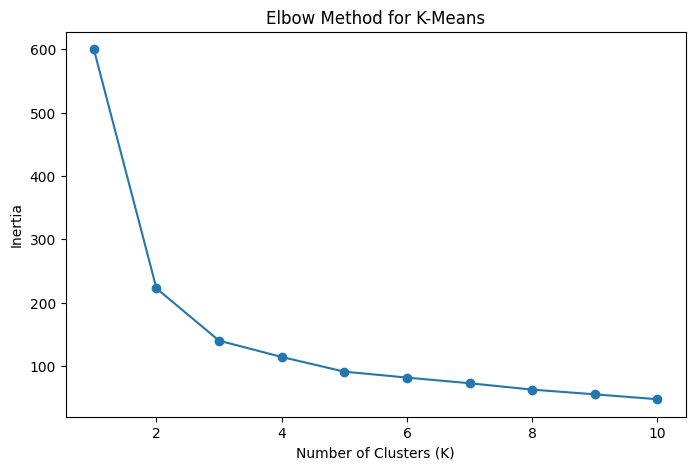

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), inertia, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")

plt.show()

The Elbow Method was used to determine the optimal number of clusters. The plot shows a significant decrease in inertia up to approximately K = 3, after which the improvement becomes smaller. Therefore, 3 clusters were selected for K-Means.

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("Cluster labels:")
print(kmeans_labels)

Cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


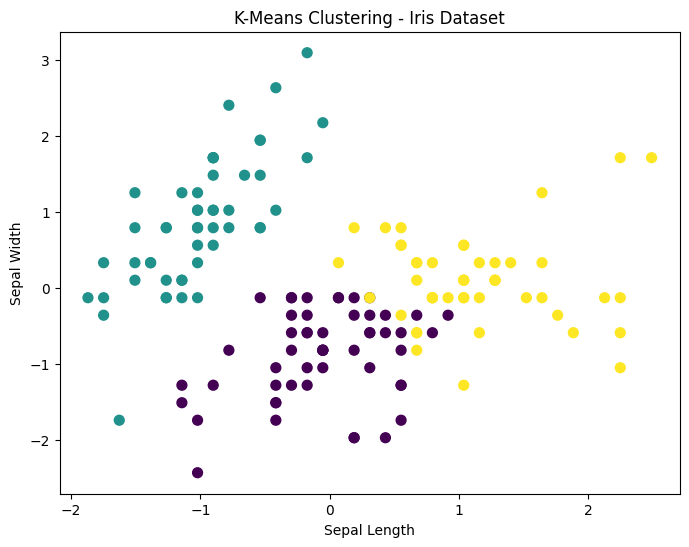

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=50
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("K-Means Clustering - Iris Dataset")

plt.show()

The scatter plot shows the Iris samples grouped into three clusters using K-Means. The clusters are represented by different colors. Some overlap can be observed because the first two features do not completely separate all three groups.

In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("PCA shape:", X_pca.shape)

Original shape: (150, 4)
PCA shape: (150, 2)


In [ ]:
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(pca.explained_variance_ratio_.sum())

Explained Variance Ratio:
[0.72962445 0.22850762]

Total Explained Variance:
0.9581320720000166


The first two principal components explain approximately 96% of the total variance in the dataset. Therefore, the two-dimensional PCA representation preserves most of the information from the original four features.

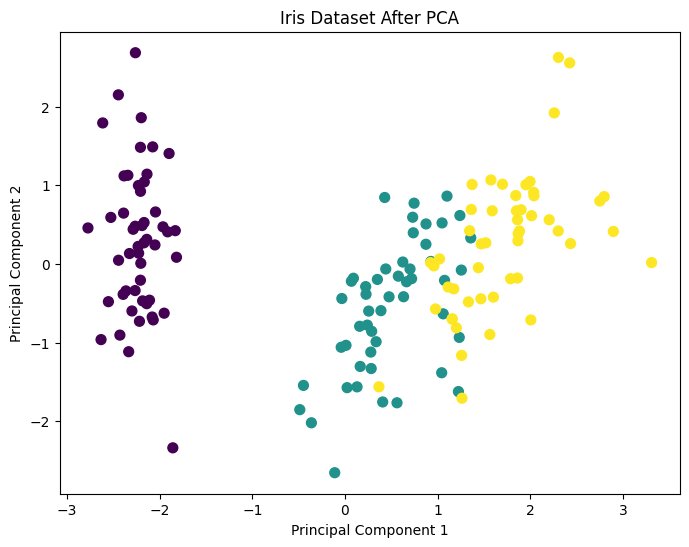

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Iris Dataset After PCA")

plt.show()

In [ ]:
kmeans_pca = KMeans(n_clusters=3, random_state=42, n_init=10)

pca_labels = kmeans_pca.fit_predict(X_pca)

print("K-Means on PCA data completed.")

K-Means on PCA data completed.


In [ ]:
original_silhouette = silhouette_score(X_scaled, kmeans_labels)
pca_silhouette = silhouette_score(X_pca, pca_labels)

print("Silhouette Score - Original Data:", original_silhouette)
print("Silhouette Score - PCA Data:", pca_silhouette)

Silhouette Score - Original Data: 0.45994823920518635
Silhouette Score - PCA Data: 0.5091683341538228


K-Means was applied to both the original standardized data and the PCA-reduced data. The silhouette scores were compared to evaluate the quality of the clusters. PCA reduced the dimensionality from four features to two while retaining most of the dataset's variance.

In [ ]:
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

print("Hierarchical clustering completed.")

Hierarchical clustering completed.


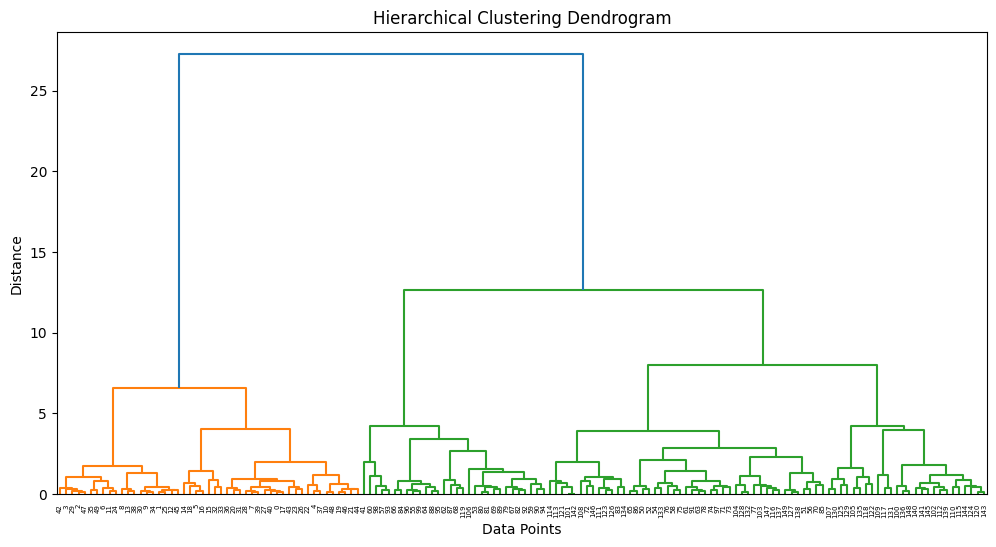

In [ ]:
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")

plt.show()

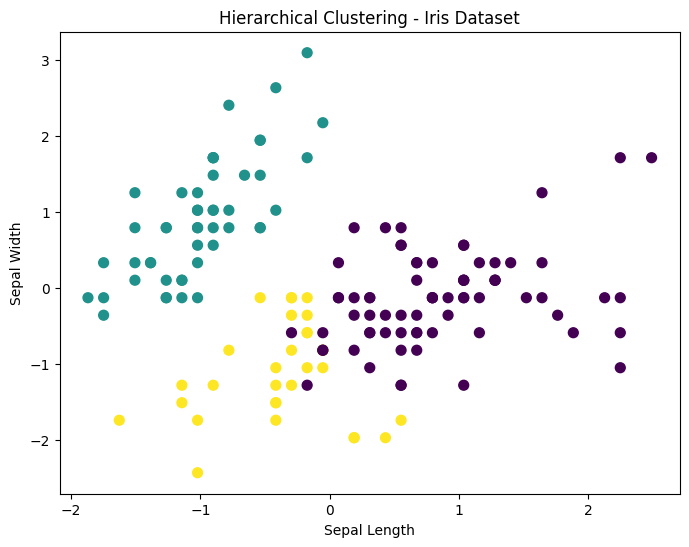

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=hierarchical_labels,
    cmap="viridis",
    s=50
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("Hierarchical Clustering - Iris Dataset")

plt.show()

In [ ]:
hierarchical_silhouette = silhouette_score(
    X_scaled,
    hierarchical_labels
)

print("K-Means Silhouette Score:", original_silhouette)
print("Hierarchical Silhouette Score:", hierarchical_silhouette)

K-Means Silhouette Score: 0.45994823920518635
Hierarchical Silhouette Score: 0.4466890410285909


K-Means and Hierarchical Clustering were both applied using three clusters. Their silhouette scores were compared to evaluate cluster separation. Both methods produced meaningful clusters, although their exact cluster assignments may differ because they use different clustering approaches.

In [ ]:
dbscan = DBSCAN(eps=0.5, min_samples=5)

dbscan_labels = dbscan.fit_predict(X_scaled)

print("DBSCAN labels:")
print(dbscan_labels)

DBSCAN labels:
[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1 -1  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0 -1 -1  0  0  0  0  0  0  0 -1  0  0  0  0  0  0
  0  0  1  1  1  1  1  1 -1 -1  1 -1 -1  1 -1  1  1  1  1  1 -1  1  1  1
 -1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1 -1  1  1  1  1  1 -1  1  1
  1  1 -1  1 -1  1  1  1  1 -1 -1 -1 -1 -1  1  1  1  1 -1  1  1 -1 -1 -1
  1  1 -1  1  1 -1  1  1  1 -1 -1 -1  1  1  1 -1 -1  1  1  1  1  1  1  1
  1  1  1  1 -1  1]


In [ ]:
unique_labels = set(dbscan_labels)

print("Unique labels:", unique_labels)

if -1 in unique_labels:
    n_clusters = len(unique_labels) - 1
    n_noise = list(dbscan_labels).count(-1)
else:
    n_clusters = len(unique_labels)
    n_noise = 0

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

Unique labels: {np.int64(0), np.int64(1), np.int64(-1)}
Number of clusters: 2
Number of noise points: 34


In [ ]:
eps_values = [0.3, 0.5, 0.7, 1.0]
min_samples_values = [3, 5, 7]

for eps in eps_values:
    for min_samples in min_samples_values:

        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = dbscan.fit_predict(X_scaled)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)

        print(
            "eps =", eps,
            "min_samples =", min_samples,
            "clusters =", n_clusters,
            "noise =", n_noise
        )

eps = 0.3 min_samples = 3 clusters = 10 noise = 84
eps = 0.3 min_samples = 5 clusters = 3 noise = 120
eps = 0.3 min_samples = 7 clusters = 2 noise = 129
eps = 0.5 min_samples = 3 clusters = 7 noise = 17
eps = 0.5 min_samples = 5 clusters = 2 noise = 34
eps = 0.5 min_samples = 7 clusters = 5 noise = 46
eps = 0.7 min_samples = 3 clusters = 2 noise = 5
eps = 0.7 min_samples = 5 clusters = 2 noise = 6
eps = 0.7 min_samples = 7 clusters = 2 noise = 16
eps = 1.0 min_samples = 3 clusters = 2 noise = 1
eps = 1.0 min_samples = 5 clusters = 2 noise = 3
eps = 1.0 min_samples = 7 clusters = 2 noise = 3


In [ ]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

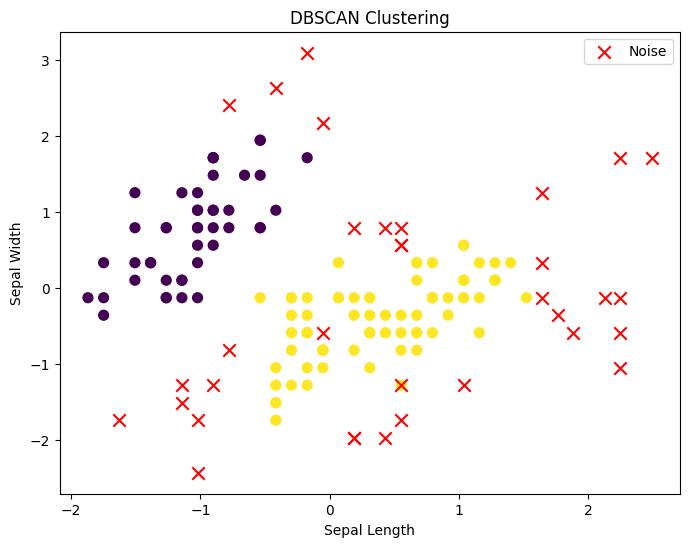

In [ ]:
plt.figure(figsize=(8, 6))

# Normal points
normal_points = dbscan_labels != -1

plt.scatter(
    X_scaled[normal_points, 0],
    X_scaled[normal_points, 1],
    c=dbscan_labels[normal_points],
    cmap="viridis",
    s=50
)

# Noise points
noise_points = dbscan_labels == -1

plt.scatter(
    X_scaled[noise_points, 0],
    X_scaled[noise_points, 1],
    c="red",
    marker="x",
    s=80,
    label="Noise"
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("DBSCAN Clustering")
plt.legend()

plt.show()

In [ ]:
dbscan_unique = set(dbscan_labels)

dbscan_clusters = len(dbscan_unique) - (
    1 if -1 in dbscan_unique else 0
)

print("K-Means clusters:", 3)
print("DBSCAN clusters:", dbscan_clusters)

K-Means clusters: 3
DBSCAN clusters: 2


In [ ]:
if dbscan_clusters >= 2:
    dbscan_silhouette = silhouette_score(
        X_scaled,
        dbscan_labels
    )

    print("K-Means Silhouette Score:", original_silhouette)
    print("DBSCAN Silhouette Score:", dbscan_silhouette)
else:
    print("Silhouette score cannot be calculated because DBSCAN produced fewer than 2 clusters.")

K-Means Silhouette Score: 0.45994823920518635
DBSCAN Silhouette Score: 0.35651648142700726


K-Means requires the number of clusters to be specified in advance, while DBSCAN determines clusters based on data density and can identify noise points. Therefore, the two algorithms may produce different numbers of clusters and different assignments.

In [ ]:
comparison = pd.DataFrame({
    "Method": [
        "K-Means",
        "Hierarchical Clustering",
        "DBSCAN"
    ],
    "Number of Clusters": [
        3,
        len(set(hierarchical_labels)),
        dbscan_clusters
    ],
    "Silhouette Score": [
        original_silhouette,
        hierarchical_silhouette,
        dbscan_silhouette if dbscan_clusters >= 2 else np.nan
    ]
})

print(comparison.round(4))

                    Method  Number of Clusters  Silhouette Score
0                  K-Means                   3            0.4599
1  Hierarchical Clustering                   3            0.4467
2                   DBSCAN                   2            0.3565


In this assignment, the Iris dataset was analyzed using K-Means, PCA, Hierarchical Clustering, and DBSCAN. The Elbow Method was used to determine a suitable number of clusters for K-Means, with three clusters being selected. PCA reduced the original four features to two principal components while preserving most of the dataset's variance. Hierarchical Clustering was visualized using a dendrogram and compared with K-Means. DBSCAN was also applied with different values of eps and min_samples to observe their effects on the clustering results and noise detection. The clustering methods were compared using silhouette scores and visualizations.